In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def reward(state, action):
    if state==0 and action==1:
        return 1
    elif state==3 and action==1:
        return 5
    else:
        return 0

def transition_prob(state, action, next_state):
  if state == 0 and action == 1 and next_state == 1:
    return 1.0
  elif state == 1 and action == 1 and next_state == 2:
    return 1.0
  elif state == 2 and action == 1 and next_state == 3:
    return 1.0
  elif state == 3 and action == 0 and next_state == 2:
    return 1.0
  elif state == next_state:
    return 0.5
  else:
    return 0.0

#bellman equation function

In [3]:
def bellman_eqn(value, gamma):
  new_value = np.zeros_like(value, dtype=float)
  num_states, num_actions = value.shape

  for state in range(num_states):
    for action in range(num_actions):
      action_value = 0.0
      for next_state in range(num_states):
        prob = transition_prob(state, action, next_state)
        r = reward(state, action)
        action_value += prob * (r + gamma * np.max(value[next_state, :]))
      new_value[state, action] = action_value

  return new_value

Iteration 1 Value Function:
 [[0.  1.5]
 [0.  0. ]
 [0.  0. ]
 [0.  2.5]]


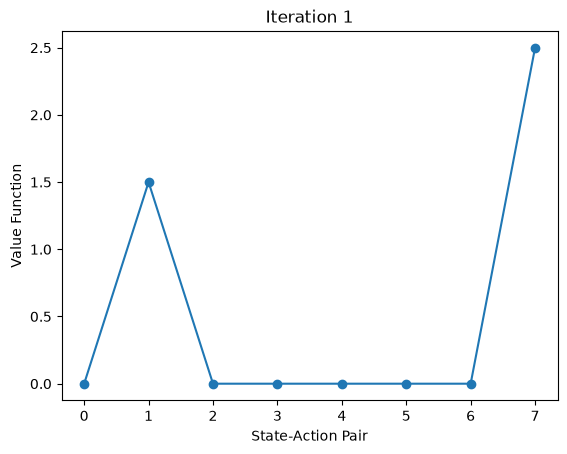

Iteration 2 Value Function:
 [[0.675 2.175]
 [0.    0.   ]
 [0.    2.25 ]
 [1.125 3.625]]


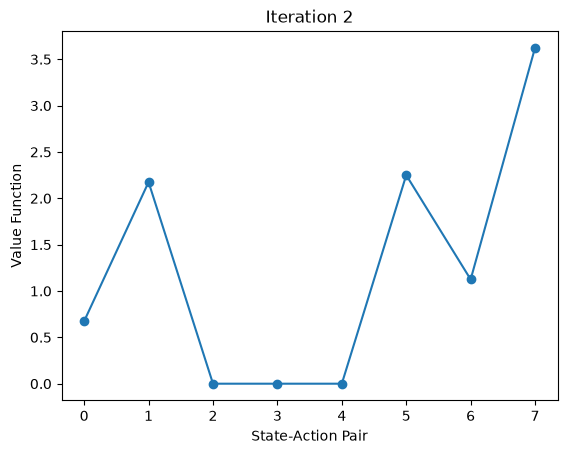

Iteration 3 Value Function:
 [[0.97875 2.47875]
 [0.      2.025  ]
 [1.0125  4.275  ]
 [3.65625 4.13125]]


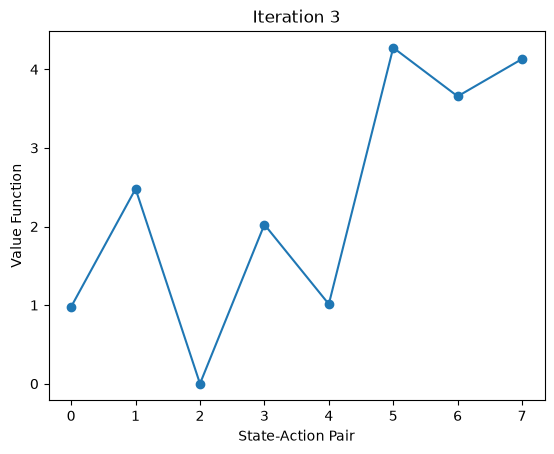

Iteration 4 Value Function:
 [[1.1154375 4.4379375]
 [0.91125   4.75875  ]
 [1.92375   5.641875 ]
 [5.7065625 4.3590625]]


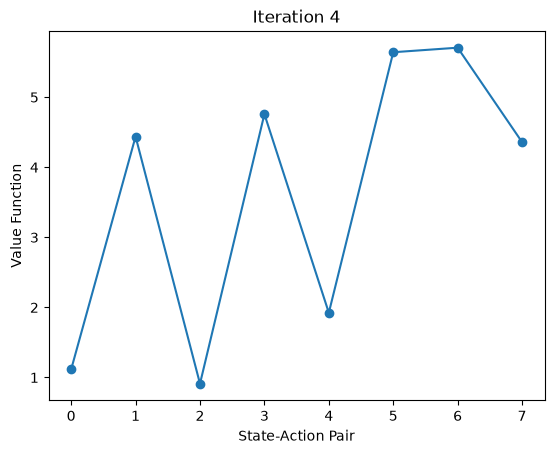

Iteration 5 Value Function:
 [[1.99707187 7.77994688]
 [2.1414375  7.219125  ]
 [2.53884375 7.67475   ]
 [7.64564063 5.06795313]]


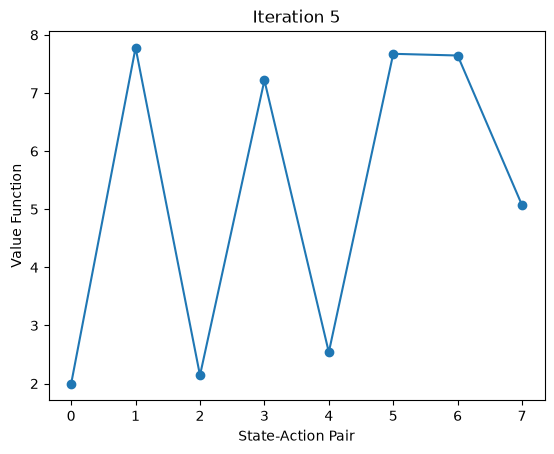

Optimal Value Function:  [[1.99707187 7.77994688]
 [2.1414375  7.219125  ]
 [2.53884375 7.67475   ]
 [7.64564063 5.06795313]]


In [4]:
def main():
    value = np.zeros((4,2))
    gamma = 0.9

    #compute optimal value function
    for i in range(5):
        value = bellman_eqn(value, gamma)
        print(f"Iteration {i + 1} Value Function:\n", value)

        plt.figure()
        plt.plot(value.flatten(), marker="o")
        plt.xlabel("State-Action Pair")
        plt.ylabel("Value Function")
        plt.title(f"Iteration {i + 1}")
        plt.show()

    print('Optimal Value Function: ', value)

if __name__ == "__main__":
    main()